# 🚀 EDA Nivel Avanzado — Normalización, segunda fuente, calidad y gráficos interactivos

Este notebook cierra el nivel avanzado del proyecto. Cambia una cosa respecto a los anteriores:
**la limpieza ya no vive aquí, vive en `src/limpieza.py`** — funciones reutilizables que
importamos. Si mañana hay un dashboard o tests, usan exactamente el mismo código.

**Lo que aporta este nivel:**

| Requisito | Cómo se cumple |
|---|---|
| Normalización justa | Tasas **por cada 100.000 habitantes** (no totales crudos) |
| Segunda fuente (merge) | **US Census Bureau**: población y región de cada estado |
| Datos de calidad dudosa | Función `comprobar_calidad()`: acumulados que bajan, imposibles anatómicos, reconciliaciones |
| Transformación justificada | Media móvil 7 días y **escala logarítmica** (distribución muy sesgada) |
| Segmentos | Comparación por **regiones del Census** y por olas/periodos |
| Interactividad | Gráficos **plotly**: mapa coroplético y líneas con hover |
| Código reutilizable | `src/limpieza.py` (todo el pipeline de limpieza) |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sys.path.append("..")  # para importar src/ desde la carpeta notebooks/
from src.limpieza import (  # noqa: E402
    URL_POBLACION, cargar_crudo, cargar_poblacion, comprobar_calidad,
    integrar_poblacion, leer_o_descargar, limpiar,
)

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("../assets")
df_crudo = cargar_crudo()
df = limpiar(df_crudo)
print(f"Dataset limpio (desde src/limpieza.py): {df.shape}")

Dataset limpio (desde src/limpieza.py): (20780, 16)


---

## 1️⃣ Segunda fuente de datos: población del Census Bureau

El problema de fondo de todo el proyecto: **comparar California con Wyoming por totales
es comparar manzanas con naranjas** (39 millones de habitantes vs. 580.000).
Para comparar con justicia necesitamos el **denominador**: la población de cada estado.

La traemos del **US Census Bureau** (fuente oficial de EE. UU., la misma que hace el
censo) y la **mezclamos (`merge`)** con nuestros datos por la llave `FIPS`, el código
oficial con el que el Census identifica cada estado — el dataset COVID lo trae en su
columna `fips`.

> Nota de honestidad: los territorios menores (Samoa Americana, Guam, Marianas, Islas
> Vírgenes) **no aparecen en este fichero del Census**, así que quedan fuera de las
> tasas. Es un `inner join` deliberado: no se divide lo que no se conoce.

In [2]:
# Descarga con cache (igual que los datos COVID): solo la primera vez va a la red
leer_o_descargar(URL_POBLACION, Path("../data/raw/poblacion_census.csv"))
poblacion = cargar_poblacion()
display(poblacion.head(3))
print(f"{len(poblacion)} unidades con datos de poblacion | "
      f"poblacion total: {poblacion['poblacion'].sum():,.0f}")
print(poblacion["region"].value_counts().to_string())

Leyendo cache local: ..\data\raw\poblacion_census.csv


,fips,estado_nombre,region,poblacion
14,1,Alabama,Sur,5031864
15,2,Alaska,Oeste,732964
16,4,Arizona,Oeste,7186683


52 unidades con datos de poblacion | poblacion total: 334,808,490
region
Sur                        17
Oeste                      13
Medio Oeste                12
Noreste                     9
Sin región (territorio)     1


In [3]:
# MERGE + tasas por 100.000 habitantes (la normalizacion que da sentido a la comparacion)
completo = integrar_poblacion(df, df_crudo, poblacion)

sin_pob = completo.loc[completo["poblacion"].isna(), "state"].unique().tolist()
print(f"Estados/territorios SIN poblacion (fuera de tasas): {sin_pob}")

# Estado a final de serie: muertes totales vs. muertes por 100k — el ranking cambia
final = (completo.dropna(subset=["poblacion"])
         .groupby("state")
         .agg(muertes=("death", "max"), poblacion=("poblacion", "first"),
              region=("region", "first")))
final["muertes_100k"] = (final["muertes"] / final["poblacion"] * 100_000).round(1)

comparacion = pd.DataFrame({
    "Top por TOTALES": final["muertes"].nlargest(8).index,
    "Top por TASA/100k": final["muertes_100k"].nlargest(8).index,
})
print("\nEl ranking cambia al normalizar:")
display(comparacion)
print("Top tasa:")
display(final.nlargest(8, "muertes_100k")[["muertes", "poblacion", "muertes_100k", "region"]])

Estados/territorios SIN poblacion (fuera de tasas): ['AS', 'GU', 'MP', 'VI']

El ranking cambia al normalizar:


,Top por TOTALES,Top por TASA/100k
0,CA,NJ
1,TX,MA
2,NY,RI
3,FL,MS
4,PA,AZ
5,NJ,CT
6,IL,SD
7,GA,LA


Top tasa:


,muertes,poblacion,muertes_100k,region
state,,,,
NJ,23574.0,9272392.0,254.2,Noreste
MA,16417.0,6997713.0,234.6,Noreste
RI,2547.0,1096444.0,232.3,Noreste
MS,6808.0,2958409.0,230.1,Sur
AZ,16328.0,7186683.0,227.2,Oeste
CT,7704.0,3577586.0,215.3,Noreste
SD,1900.0,887852.0,214.0,Medio Oeste
LA,9748.0,4652022.0,209.5,Sur


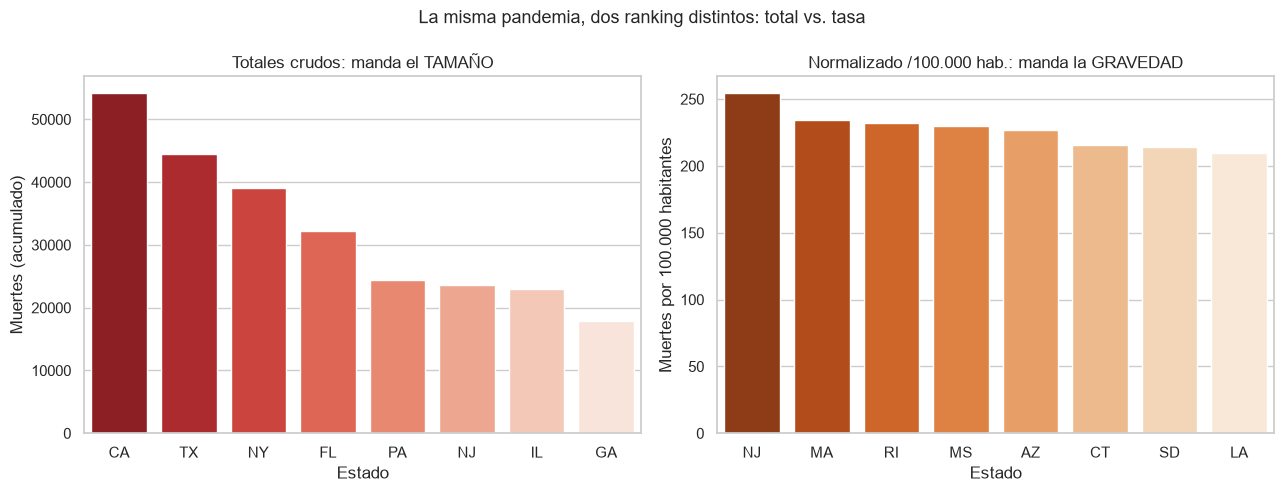

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

top_t = final.nlargest(8, "muertes")
sns.barplot(x=top_t.index, y=top_t["muertes"], hue=top_t.index,
            palette="Reds_r", legend=False, ax=axes[0])
axes[0].set_title("Totales crudos: manda el TAMAÑO")
axes[0].set_xlabel("Estado")
axes[0].set_ylabel("Muertes (acumulado)")

top_r = final.nlargest(8, "muertes_100k")
sns.barplot(x=top_r.index, y=top_r["muertes_100k"], hue=top_r.index,
            palette="Oranges_r", legend=False, ax=axes[1])
axes[1].set_title("Normalizado /100.000 hab.: manda la GRAVEDAD")
axes[1].set_xlabel("Estado")
axes[1].set_ylabel("Muertes por 100.000 habitantes")

fig.suptitle("La misma pandemia, dos ranking distintos: total vs. tasa", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "avanzado_total_vs_tasa.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 2️⃣ Datos de calidad dudosa: encontrar lo imposible y documentar qué hicimos

Aquí no miramos nulos (eso ya estaba), sino **datos que no cuadran**:

1. **Acumulados que bajan**: si ayer había 100 muertes registradas y hoy 97, alguien
   corrigió registros duplicados. Un acumulado «que retrocede» es imposible en la vida
   real, pero muy real en los datos administrativos.
2. **Inconsistencias entre columnas**: ¿puede haber más pacientes en UCI que
   hospitalizados? Anatómicamente, no.
3. **Reconciliación**: ¿la suma de los incrementos diarios da el acumulado final?

La función `comprobar_calidad()` (en `src/limpieza.py`) está hecha para esto y
se puede ejecutar en cualquier proyecto que use estos datos.

In [5]:
problemas = comprobar_calidad(completo)

print("1) ACUMULADOS QUE BAJAN (correcciones de registro):")
display(problemas["resumen_acumulados_que_bajan"].to_frame())

print("\n2) INCONSISTENCIAS ENTRE COLUMNAS:")
print(f"   UCI > hospitalizados: {len(problemas['uci_mayor_que_hospitalizados'])} dias-estado",
      "(ej.: Guam reporta 2 en UCI con 1 hospitalizado)")
print(f"   Respirador > UCI: {len(problemas['respirador_mayor_que_uci'])} dias-estado",
      "(posible: algunos estados reportan respiradores fuera de UCI, p.ej. DC en abril 2020)")
display(problemas["respirador_mayor_que_uci"].head(3))

print("\n3) RECONCILIACION incrementos vs. acumulado:")
rec = problemas["reconciliacion_positivos"]
print(f"   {len(rec)} estados no cuadran al centimo; max. diferencia: "
      f"{rec['diferencia'].abs().max():.0f} positivos")
display(rec.reindex(rec["diferencia"].abs().sort_values(ascending=False).index).head(4))

1) ACUMULADOS QUE BAJAN (correcciones de registro):


,n_dias
positive_baja,24
death_baja,73
totalTestResults_baja,49



2) INCONSISTENCIAS ENTRE COLUMNAS:
   UCI > hospitalizados: 39 dias-estado (ej.: Guam reporta 2 en UCI con 1 hospitalizado)
   Respirador > UCI: 102 dias-estado (posible: algunos estados reportan respiradores fuera de UCI, p.ej. DC en abril 2020)


,date,state,inIcuCurrently,onVentilatorCurrently
2986,2020-04-23,DC,120.0,200.0
5078,2020-12-05,HI,14.0,17.0
5079,2020-12-06,HI,14.0,17.0



3) RECONCILIACION incrementos vs. acumulado:
   17 estados no cuadran al centimo; max. diferencia: 53 positivos


,positivos_acum,suma_incrementos,diferencia
state,,,
CA,3501394.0,3501341,-53.0
MI,656072.0,656058,-14.0
PR,101632.0,101627,-5.0
IL,1198335.0,1198331,-4.0


In [6]:
# DECISIONES sobre calidad dudosa (documentadas):
# - Acumulados que bajan y negativos diarios: SE CONSERVAN. Son correcciones de los
#   estados; borrarlos inflaria los totales. Para tendencias, media movil de 7 dias.
# - UCI > hospitalizados (39 dias-estado): SE CONSERVA, marcado. Casi todo en territorios
#   con conteos de 1-2 pacientes (un +/- los desordena). No afecta a conclusiones.
# - Respirador > UCI (102 dias-estado): SE CONSERVA. Es posible fuera de UCI;
#   ademas, estas dos columnas tienen 44-56% de nulos: el informe usa solo hospitalizados.
# - Reconciliacion (max. 53 de 3,5 millones en CA): SE IGNORA el desfase. Es ruido
#   de redondeo/correcciones, <0.002%: no cambia ninguna conclusion.

print("Decisiones registradas arriba; ademas estan en el informe ejecutivo (seccion 5).")

Decisiones registradas arriba; ademas estan en el informe ejecutivo (seccion 5).


---

## 3️⃣ Transformación justificada: escala logarítmica

**El problema:** las muertes diarias por estado tienen una distribución **extremadamente
sesgada** — la mediana está en 6 y hay picos de 2.559 (el percentil 99 está en 265).
En una escala lineal, la caja del boxplot queda aplastada en el suelo y todo lo demás es
un montón de puntos inseparables.

**La transformación:** escala logarítmica (`log1p` = log(1+x) para poder dibujar los 0).
Convierte «10 veces más» en «un paso igual en el eje», así los órdenes de magnitud
conviven en la misma figura.

**Cuándo NO usarla:** nunca en las cifras que se reportan al CEO — un gráfico log
«aplana» visualmente diferencias que importan. Aquí sirve para **explorar la forma**
de la distribución, y el informe sigue con cifras lineales.

> La otra transformación del proyecto es la **media móvil de 7 días** (ya usada en el
> nivel medio): suaviza el reporte administrativo de fin de semana.

C:\Users\CarlaDC\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\CarlaDC\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


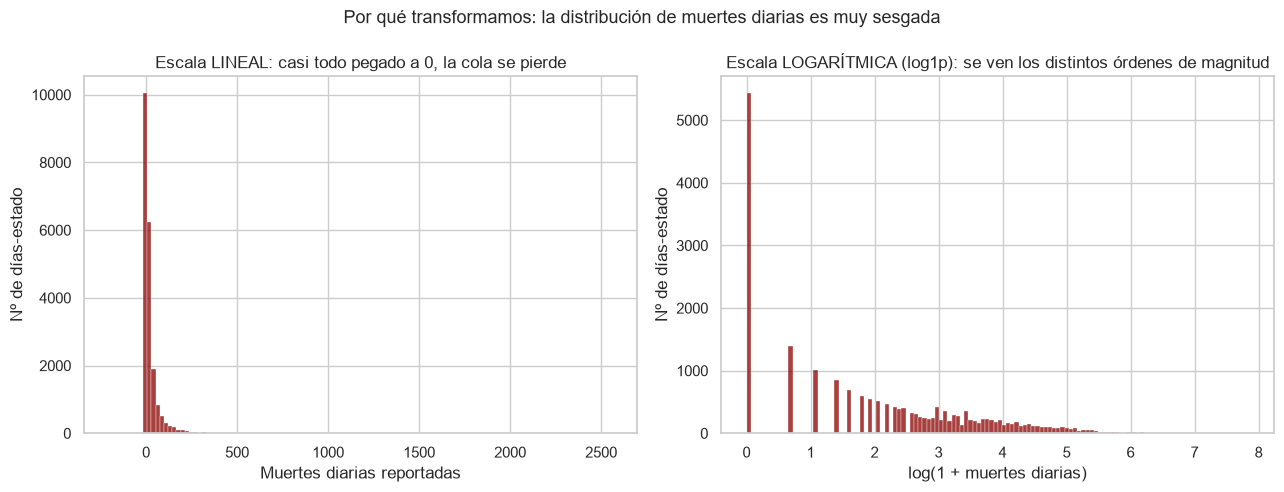

Mediana: 6 muertes/día | percentil 90: 64 | percentil 99: 265 -> 100 días-estado por encima del 99% de los días son cola, no error.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["deathIncrease"], bins=120, ax=axes[0], color="darkred")
axes[0].set_title("Escala LINEAL: casi todo pegado a 0, la cola se pierde")
axes[0].set_xlabel("Muertes diarias reportadas")
axes[0].set_ylabel("Nº de días-estado")

sns.histplot(np.log1p(df["deathIncrease"]), bins=120, ax=axes[1], color="darkred")
axes[1].set_title("Escala LOGARÍTMICA (log1p): se ven los distintos órdenes de magnitud")
axes[1].set_xlabel("log(1 + muertes diarias)")
axes[1].set_ylabel("Nº de días-estado")

fig.suptitle("Por qué transformamos: la distribución de muertes diarias es muy sesgada", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "avanzado_escala_log.png", dpi=150, bbox_inches="tight")
plt.show()

q = df["deathIncrease"].quantile([0.5, 0.9, 0.99]).round(0)
print(f"Mediana: {q[0.5]:.0f} muertes/día | percentil 90: {q[0.9]:.0f} | percentil 99: {q[0.99]:.0f}"
      " -> 100 días-estado por encima del 99% de los días son cola, no error.")

---

## 4️⃣ Comparar segmentos: regiones del Census

La segunda fuente no solo trae población: trae la **región oficial** de cada estado
(Noreste, Medio Oeste, Sur, Oeste). Es un corte mucho más informativo que mirar
56 estados sueltos — y permite ver **si las olas fueron fenómenos de una zona**.

Tasas por región = (suma de muertes de la región) / (población de la región) × 100.000
— se agrega el numerador y el denominador **antes** de dividir (nunca la media de
las medias).

,muertes,poblacion,muertes_100k
region,,,
Noreste,115718.0,57430477.0,201.5
Medio Oeste,107743.0,68969794.0,156.2
Sur,190177.0,126465281.0,150.4
Oeste,99291.0,78661381.0,126.2
Sin región (territorio),2062.0,3281557.0,62.8


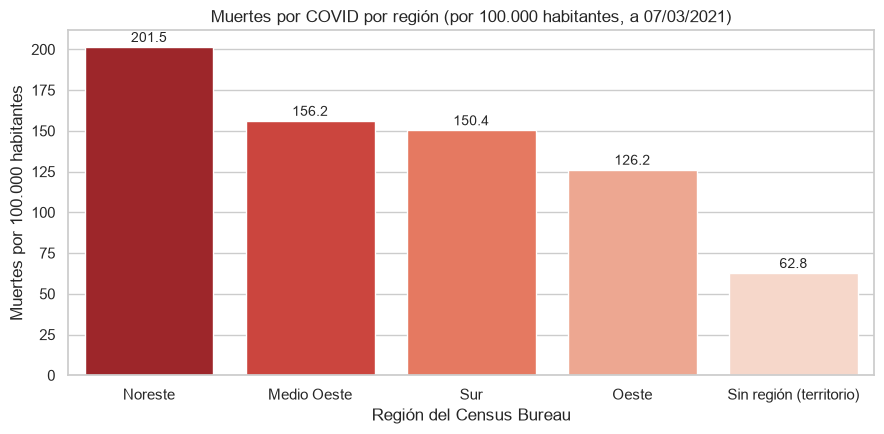

In [8]:
# Tasa acumulada por region a final de serie (numerador y denominador agregados)
con_pob = completo.dropna(subset=["poblacion"])
ultimo = con_pob.groupby("state").last().reset_index()
tasa_region = (
    ultimo.groupby("region")
    .agg(muertes=("death", "sum"), poblacion=("poblacion", "sum"))
    .assign(muertes_100k=lambda t: (t["muertes"] / t["poblacion"] * 100_000).round(1))
    .sort_values("muertes_100k", ascending=False)
)
display(tasa_region)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=tasa_region.index, y=tasa_region["muertes_100k"],
            hue=tasa_region.index, palette="Reds_r", legend=False, ax=ax)
for i, v in enumerate(tasa_region["muertes_100k"]):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
ax.set_title("Muertes por COVID por región (por 100.000 habitantes, a 07/03/2021)")
ax.set_xlabel("Región del Census Bureau")
ax.set_ylabel("Muertes por 100.000 habitantes")
plt.tight_layout()
plt.savefig(FIG_DIR / "avanzado_tasa_por_region.png", dpi=150, bbox_inches="tight")
plt.show()

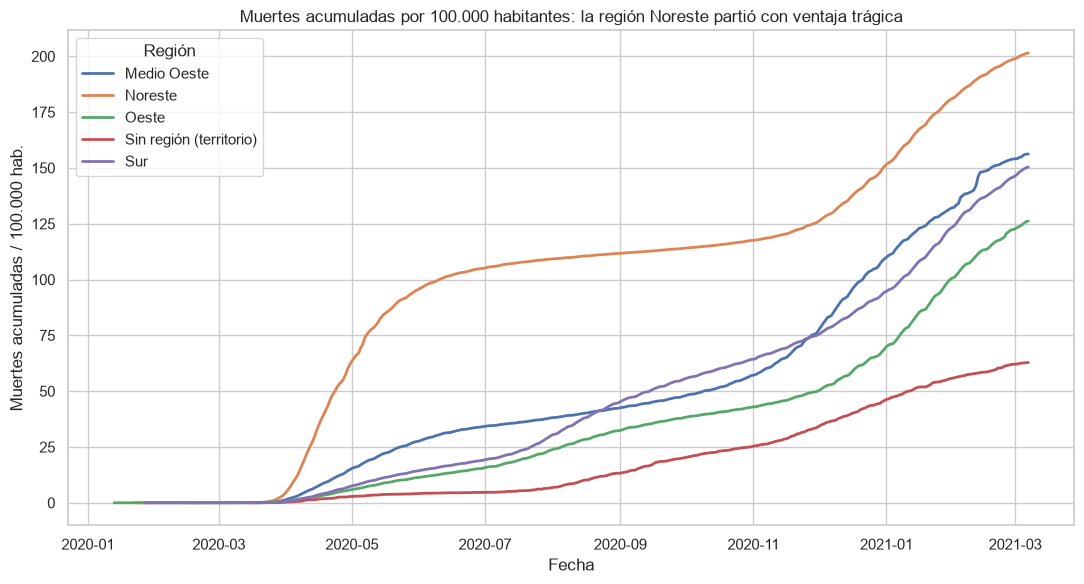

In [9]:
# Tendencia por region: agregamos numerador y denominador ANTES de dividir
# (nunca sumar tasas de estados individuales: no es lo mismo suma de ratios
# que ratio de sumas)
por_region = completo.dropna(subset=["poblacion"]).copy()
agregado = (por_region.groupby(["date", "region"], as_index=False)
            .agg(muertes=("death", "sum")))
# poblacion de la region: suma de cada estado UNA sola vez (no por cada dia)
pob_region = (por_region.groupby(["region", "state"])["poblacion"].first()
              .groupby("region").sum())
agregado["muertes_100k_dia"] = (agregado["muertes"]
                                / agregado["region"].map(pob_region) * 100_000)
serie_region = agregado

fig, ax = plt.subplots(figsize=(11, 6))
for reg, g in serie_region.groupby("region"):
    ax.plot(g["date"], g["muertes_100k_dia"], lw=2, label=reg)
ax.set_title("Muertes acumuladas por 100.000 habitantes: la región Noreste partió con ventaja trágica")
ax.set_xlabel("Fecha")
ax.set_ylabel("Muertes acumuladas / 100.000 hab.")
ax.legend(title="Región")
plt.tight_layout()
plt.savefig(FIG_DIR / "avanzado_tendencia_region.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 5️⃣ Gráficos interactivos con plotly

Hasta aquí, todo el mundo podía ver los gráficos pero no **tocarlos**. Con plotly el
lector puede pasar el ratón por un estado, apagar series y leer los valores exactos
sin ejecutar nada. Son dos vistas que los gráficos estáticos no pueden dar:

1. **Mapa coroplético**: la tasa de muertes por estado, coloreada — se ve el patrón
   geográfico de un vistazo (el Noreste, el sur de Luisiana-Misisipi...).
2. **Líneas por región con `hover`**: valor exacto en cada fecha.

In [10]:
# 1) Mapa coroplético de EE. UU.: muertes por 100k a final de serie
mapa = ultimo.copy()
mapa["muertes_100k"] = (mapa["death"] / mapa["poblacion"] * 100_000).round(1)
# Puerto Rico aparece en el Census pero fuera del `scope="usa"` del mapa: se marca
fig_mapa = px.choropleth(
    mapa,
    locations="state",
    locationmode="USA-states",
    color="muertes_100k",
    scope="usa",
    color_continuous_scale="YlOrRd",
    hover_name="state",
    hover_data={"muertes_100k": ":.1f", "death": ":,.0f", "poblacion": ":,.0f"},
    labels={"muertes_100k": "Muertes/100k", "death": "Muertes", "poblacion": "Población"},
    title="Muertes por COVID-19 por cada 100.000 habitantes (a 07/03/2021)",
)
fig_mapa.update_layout(margin=dict(l=0, r=0, t=40, b=0))
fig_mapa.show()

In [11]:
# 2) Lineas interactivas por region con valor al pasar el ratón
fig_lineas = px.line(
    serie_region,
    x="date",
    y="muertes_100k_dia",
    color="region",
    labels={"date": "Fecha", "muertes_100k_dia": "Muertes acumuladas / 100.000 hab.",
            "region": "Región"},
    title="Evolución por región: la pandemia golpeó antes en el Noreste y con más fuerza en el Sur",
)
fig_lineas.update_layout(hovermode="x unified", legend_title_text="Región")
fig_lineas.show()

In [12]:
# Guardamos el dataset ya enriquecido (con poblacion, region y tasas) por si lo
# necesita el dashboard o un siguiente análisis
out = Path("../data/processed/covid_avanzado.csv")
completo.to_csv(out, index=False)
print(f"Dataset enriquecido: {out} -> {completo.shape[0]:,} filas x {completo.shape[1]} columnas")

Dataset enriquecido: ..\data\processed\covid_avanzado.csv -> 20,780 filas x 22 columnas


---

## 🔟 Conclusiones del nivel avanzado

1. **Normalizar cambia las conclusiones, no solo los números.** Por totales mandan
   California, Texas y Nueva York; por cada 100.000 habitantes suben **Nueva Jersey (254),
   Massachusetts (235) y Rhode Island (232)** — el noreste. California ni siquiera
   entra en el top-8 de gravedad relativa. Decidir sobre totales crudos habría
   llevado a centrar los recursos donde había más *gente*, no donde había más *riesgo*.
2. **La segunda fuente resolvió el problema de comparabilidad** (población) y añadió
   un eje de análisis nuevo (región): el Noreste partió en marzo-abril de 2020 con una
   tasa que el resto no alcanzó hasta el invierno.
3. **Los datos «imposibles» sí existen y están explicados**: acumulados que bajan
   (correcciones), UCI > hospitalizados (territorios con 1-2 pacientes) y pequeñas
   descuadres de reconciliación (<0,002%). Documentados y conservados donde procede:
   borrarlos habría sido manipular la historia.
4. **La distribución de muertes diarias es tan sesgada que la escala lineal la ocultaba**:
   mediana de 6 muertes/día, percentil 99 en 265 y picos de 2.559. La escala
   logarítmica sirve para explorar (nunca para reportar al CEO).